<a href="https://colab.research.google.com/github/Margarrret/AI_boostcamp_ladm/blob/master/%D0%BC%D1%83%D0%BB%D1%8C%D1%82%D0%B8%D0%BB%D0%B5%D0%B9%D0%B1%D0%BB_%D0%BA%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D1%8F_(%D0%BF%D0%BB%D0%B0%D1%81%D1%82%D0%B8%D0%BD%D0%B0%2C_%D1%88%D1%82%D0%B8%D1%84%D1%82).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install optuna

In [ ]:
import os
from google.colab import drive
import shutil
import zipfile
from pathlib import Path
import xml.etree.ElementTree as ET
import pandas as pd
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, f1_score
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import warnings
warnings.filterwarnings('ignore')

import re
from collections import Counter
from collections import defaultdict

import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import WeightedRandomSampler
from torch.optim.lr_scheduler import ReduceLROnPlateau

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
ANNOTATIONS_PATH = "/content/drive/MyDrive/Annotations "
IMAGES_ROOT = "/content/drive/MyDrive/втск/data/01-0525_cleaned"
WORKING_DIR = "/content/annotations"

if not os.path.exists(ANNOTATIONS_PATH):
    print(f"Папка не найдена: {ANNOTATIONS_PATH}")
    print("Текущее содержимое /content/drive/MyDrive/:")
    !ls -la /content/drive/MyDrive/
    raise FileNotFoundError("Укажите правильный путь к папке с аннотациями")

In [ ]:
WORKING_DIR = "/content/annotations"
os.makedirs(WORKING_DIR, exist_ok=True)

print(f"\nКопируем XML файлы из {ANNOTATIONS_PATH} в {WORKING_DIR}")

# 4. Копируем все XML файлы
xml_files_copied = 0
for file in os.listdir(ANNOTATIONS_PATH):
    if file.endswith('.xml'):
        src = os.path.join(ANNOTATIONS_PATH, file)
        dst = os.path.join(WORKING_DIR, file)
        shutil.copy2(src, dst)
        print(f"  ✓ {file} ({os.path.getsize(src)} bytes)")
        xml_files_copied += 1

print(f"\nСкопировано XML файлов: {xml_files_copied}")

zip_files = [f for f in os.listdir(ANNOTATIONS_PATH) if f.endswith('.zip')]
for zip_file in zip_files:
    print(f"\nРаспаковываем {zip_file}...")
    with zipfile.ZipFile(os.path.join(ANNOTATIONS_PATH, zip_file), 'r') as zip_ref:
        zip_ref.extractall(WORKING_DIR)
        print(f"  Распаковано в {WORKING_DIR}")


Копируем XML файлы из /content/drive/MyDrive/Annotations  в /content/annotations
  ✓ annotations 2.xml (63122 bytes)
  ✓ annotations.xml (59582 bytes)
  ✓ annotations (1).xml (58091 bytes)
  ✓ annotations (3).xml (22028 bytes)
  ✓ annotations (2).xml (59582 bytes)
  ✓ 01-0525_121_1_IMG-0001-00001_jpg.rf.7db0aa295bf84a28b3d345f71e58bb62.xml (665 bytes)
  ✓ 01-0525_116_1_IMG-0001-00002_jpg.rf.2c4de0a50877f1d2016c868b57b6968f.xml (662 bytes)
  ✓ 01-0525_117_1_IMG-0001-00002_jpg.rf.9c4c288e830ac2a64a9412c128d24e65.xml (663 bytes)
  ✓ 01-0525_128_1_IMG-0002-00001_jpg.rf.91831b7f06385c27d4e2d10a6cc55785.xml (664 bytes)
  ✓ 01-0525_114_1_IMG-0001-00001_jpg.rf.a460935be89066087460dc2308efb68d.xml (664 bytes)
  ✓ 01-0525_118_1_IMG-0001-00003_jpg.rf.712697e39e685da06eebe5aaa3456f51.xml (664 bytes)
  ✓ 01-0525_101_1_IMG-0001-00001_jpg.rf.c470be067daa1c15beaac4e59668799a.xml (664 bytes)
  ✓ 01-0525_125_1_IMG-0001-00001_jpg.rf.4e4a3add44604fc17238669c64b49cf8.xml (664 bytes)
  ✓ 01-0525_116_1_IMG-

In [ ]:
csv_path = "/content/drive/MyDrive/втск/data/Roentgen - csv.csv"
df_csv = pd.read_csv(csv_path, encoding='utf-8')

df_csv.columns = ['path_to_file', 'bone_fracture', 'projection_type', 'large_tubercle',
                  'internal_fixation_hardware', 'right_bone_fracture', 'col7', 'col8', 'col9', 'col10', 'col11']

df_csv = df_csv[['path_to_file', 'projection_type', 'internal_fixation_hardware']].copy()

df_csv['internal_fixation_hardware'] = pd.to_numeric(df_csv['internal_fixation_hardware'], errors='coerce')
df_csv = df_csv.dropna(subset=['path_to_file', 'internal_fixation_hardware'])

print(f"Всего записей в CSV: {len(df_csv)}")

Всего записей в CSV: 1285


In [ ]:
df_hardware = df_csv[df_csv['internal_fixation_hardware'] == 1].copy()
print(f"Строк с металлоконструкциями: {len(df_hardware)}")

Строк с металлоконструкциями: 221


In [ ]:
bad_paths = [
    "01-0525/139/1/IMG-0002-00001.jpg",
    "01-0525/139/1/IMG-0002-00002.jpg",
    "01-0525/151/3/IMG-0001-00001.jpg",
    "01-0525/151/3/IMG-0002-00001.jpg",
    "01-0525/154/1/IMG-0001-00001.jpg",
    "01-0525/216/1/IMG-0002-00001.jpg",
    "01-0525/216/1/IMG-0002-00002.jpg",
    "01-0525/258/1/IMG-0001-00001.jpg",
    "01-0525/258/1/IMG-0001-00002.jpg",
    "01-0525/466/1/IMG-0001-00001.jpg",
    "01-0525/466/1/IMG-0002-00001.jpg",
    "01-0525/610/1/IMG-0001-00001.jpg",
    "01-0525/650/1/IMG-0002-00001.jpg",
    "01-0525/650/1/IMG-0002-00002.jpg",
    "01-0525/227/1/IMG-0001-00001.jpg",
    "01-0525/551/1/IMG-0002-00001.jpg",
    "01-0525/524/1/IMG-0002-00001.jpg",
    "01-0525/196/1/IMG-0001-00001.jpg",
    "01-0525_158_1_IMG-0001-00005.jpg",
    "01-0525_158_1_IMG-0001-00006.jpg",
    "01-0525_383_1_IMG-0001-00004.jpg",
    "01-0525_2_1_IMG-0001-00002.jpg",
    "01-0525/2/1/IMG-0001-00003.jpg"
]

bad_filenames = set()
for path in bad_paths:
    if '/' in path:
        filename = path.split('/')[-1]
    else:
        filename = path
    bad_filenames.add(filename)
    img_match = re.search(r'(IMG-\d+-\d+)', filename)
    if img_match:
        bad_filenames.add(img_match.group(1))

print(f"Невалидных имен для удаления: {len(bad_filenames)}")

Невалидных имен для удаления: 17


In [ ]:
all_files = os.listdir(IMAGES_ROOT)
jpg_files = [f for f in all_files if f.endswith('.jpg')]

In [ ]:
real_files_map = {}
for file in jpg_files:
    full_path = os.path.join(IMAGES_ROOT, file)
    real_files_map[file] = full_path
    real_files_map[file.replace('.jpg', '')] = full_path

print(f"Создано записей в маппинге: {len(real_files_map)}")

Создано записей в маппинге: 2962


In [ ]:
def find_file_path(path_key):
    if pd.isna(path_key):
        return None
    path_key = str(path_key)
    filename = path_key + '.jpg'

    if filename in real_files_map:
        return real_files_map[filename]

    img_match = re.search(r'(IMG-\d+-\d+)', path_key)
    if img_match and img_match.group(1) in real_files_map:
        return real_files_map[img_match.group(1)]

    return None

df_hardware['filename_full'] = df_hardware['path_to_file'].apply(lambda x: str(x) + '.jpg')
df_hardware['file_path'] = df_hardware['path_to_file'].apply(find_file_path)
df_hardware['file_exists'] = df_hardware['file_path'].notna()
df_hardware['is_bad'] = df_hardware['filename_full'].isin(bad_filenames)

print(f"Всего записей с металлоконструкциями: {len(df_hardware)}")
print(f"Найдено файлов в папке: {df_hardware['file_exists'].sum()}")
print(f"Из них невалидных: {df_hardware['is_bad'].sum()}")

df_clean = df_hardware[df_hardware['file_exists'] & ~df_hardware['is_bad']].reset_index(drop=True)
print(f"После фильтрации: {len(df_clean)} изображений")

Всего записей с металлоконструкциями: 221
Найдено файлов в папке: 221
Из них невалидных: 0
После фильтрации: 221 изображений


In [ ]:
ANNOTATIONS_PATH = "/content/drive/MyDrive/Annotations "
xml_records = []

for file in os.listdir(ANNOTATIONS_PATH):
    if file.endswith('.xml'):
        file_path = os.path.join(ANNOTATIONS_PATH, file)
        try:
            tree = ET.parse(file_path)
            root = tree.getroot()

            # Для файлов с тегами image (CVAT формат)
            for img in root.findall('image'):
                img_name = img.get('name')
                has_plate = False
                has_pin = False
                has_phf = False
                has_phn = False

                for box in img.findall('box'):
                    label = box.get('label')
                    if label == 'Plate':
                        has_plate = True
                    elif label == 'Pin':
                        has_pin = True
                    elif label == 'PHF':
                        has_phf = True
                    elif label == 'PHN':
                        has_phn = True

                xml_records.append({
                    'image_name': img_name,
                    'has_plate': int(has_plate),
                    'has_pin': int(has_pin),
                    'has_phf': int(has_phf),
                    'has_phn': int(has_phn)
                })

            # Для файлов с тегами object (Roboflow формат)
            filename = root.find('filename')
            if filename is not None:
                img_name = filename.text
                has_plate = False
                has_pin = False
                has_phf = False
                has_phn = False

                for obj in root.findall('object'):
                    name = obj.find('name')
                    if name is not None:
                        if name.text == 'Plate':
                            has_plate = True
                        elif name.text == 'Pin':
                            has_pin = True
                        elif name.text == 'PHF':
                            has_phf = True
                        elif name.text == 'PHN':
                            has_phn = True

                xml_records.append({
                    'image_name': img_name,
                    'has_plate': int(has_plate),
                    'has_pin': int(has_pin),
                    'has_phf': int(has_phf),
                    'has_phn': int(has_phn)
                })
        except Exception as e:
            print(f"Ошибка при обработке {file}: {e}")

df_xml = pd.DataFrame(xml_records)
df_xml['orig_name'] = df_xml['image_name'].apply(lambda x: x.replace('.jpg', '').replace('_jpg.rf', '') if pd.notna(x) else '')
df_xml.to_csv('/content/all_xml_annotations.csv', index=False)
print(f"Создано XML аннотаций: {len(df_xml)}")

Создано XML аннотаций: 1477


In [ ]:
df_xml = pd.read_csv('/content/all_xml_annotations.csv')
print(f"Всего XML аннотаций: {len(df_xml)}")

print(f"\nМетки в XML:")
print(f"  Plate: {df_xml['has_plate'].sum()}")
print(f"  Pin: {df_xml['has_pin'].sum()}")
print(f"  PHF: {df_xml['has_phf'].sum()}")
print(f"  PHN: {df_xml['has_phn'].sum()}")

Всего XML аннотаций: 1477

Метки в XML:
  Plate: 105
  Pin: 111
  PHF: 1286
  PHN: 20


In [ ]:
# df_metal = df_xml[(df_xml['has_plate'] == 1) | (df_xml['has_pin'] == 1)].copy()
# print(f"Изображений с металлом: {len(df_metal)}")
# print(f"  Plate: {df_metal['has_plate'].sum()}")
# print(f"  Pin: {df_metal['has_pin'].sum()}")
# print(f"  И Plate и Pin: {((df_metal['has_plate'] == 1) & (df_metal['has_pin'] == 1)).sum()}")

Изображений с металлом: 216
  Plate: 105
  Pin: 111
  И Plate и Pin: 0


In [ ]:
def extract_study_id_from_name(name):
    if pd.isna(name):
        return "unknown"
    parts = str(name).split('_')
    if len(parts) >= 3:
        return f"{parts[0]}_{parts[1]}_{parts[2]}"
    return "unknown"

df_metal['study_id'] = df_metal['image_name'].apply(extract_study_id_from_name)
print(f"Уникальных исследований: {df_metal['study_id'].nunique()}")

Уникальных исследований: 82


In [ ]:
IMAGES_ROOT = "/content/drive/MyDrive/втск/data/01-0525_cleaned"

if os.path.exists(IMAGES_ROOT):
    jpg_files = [f for f in os.listdir(IMAGES_ROOT) if f.endswith('.jpg')]
    print(f"Найдено изображений в папке: {len(jpg_files)}")

    real_files_set = set(jpg_files)

    def find_image_file(image_name):
        if pd.isna(image_name):
            return None
        if image_name in real_files_set:
            return os.path.join(IMAGES_ROOT, image_name)

        base_name = image_name.split('/')[-1] if '/' in image_name else image_name
        if base_name in real_files_set:
            return os.path.join(IMAGES_ROOT, base_name)

        return None

    df_metal['file_path'] = df_metal['image_name'].apply(find_image_file)
    df_metal['file_exists'] = df_metal['file_path'].notna()

    print(f"Из них существует в папке: {df_metal['file_exists'].sum()}")
    df_metal = df_metal[df_metal['file_exists']].reset_index(drop=True)
    print(f"После фильтрации: {len(df_metal)} изображений")
else:
    print(f"Папка не найдена: {IMAGES_ROOT}")
    df_metal = df_metal.iloc[0:0].copy()


Найдено изображений в папке: 1481
Из них существует в папке: 149
После фильтрации: 149 изображений


In [ ]:
if len(df_metal) > 0:
    print(f"Всего изображений для обучения: {len(df_metal)}")
    print(f"\nМеталлоконструкции:")
    print(f"  Только Plate: {((df_metal['has_plate'] == 1) & (df_metal['has_pin'] == 0)).sum()}")
    print(f"  Только Pin: {((df_metal['has_pin'] == 1) & (df_metal['has_plate'] == 0)).sum()}")
    print(f"  И Plate и Pin: {((df_metal['has_plate'] == 1) & (df_metal['has_pin'] == 1)).sum()}")

    SEED = 42
    VAL_SIZE = 0.15
    TEST_SIZE = 0.15

    df_metal['has_hardware'] = 1

    gss1 = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED)
    train_val_idx, test_idx = next(gss1.split(
        df_metal, y=df_metal['has_hardware'], groups=df_metal['study_id']
    ))

    df_train_val = df_metal.iloc[train_val_idx].reset_index(drop=True)
    df_test = df_metal.iloc[test_idx].reset_index(drop=True)

    gss2 = GroupShuffleSplit(n_splits=1, test_size=VAL_SIZE/(1-TEST_SIZE), random_state=SEED)
    train_idx, val_idx = next(gss2.split(
        df_train_val, y=df_train_val['has_hardware'], groups=df_train_val['study_id']
    ))

    df_train = df_train_val.iloc[train_idx].reset_index(drop=True)
    df_val = df_train_val.iloc[val_idx].reset_index(drop=True)

    print(f"\nВсего: {len(df_metal)}")
    print(f"Train: {len(df_train)} (Plate: {df_train['has_plate'].sum()}, Pin: {df_train['has_pin'].sum()})")
    print(f"Val: {len(df_val)} (Plate: {df_val['has_plate'].sum()}, Pin: {df_val['has_pin'].sum()})")
    print(f"Test: {len(df_test)} (Plate: {df_test['has_plate'].sum()}, Pin: {df_test['has_pin'].sum()})")

Всего изображений для обучения: 149

Металлоконструкции:
  Только Plate: 65
  Только Pin: 84
  И Plate и Pin: 0

Всего: 149
Train: 114 (Plate: 44, Pin: 70)
Val: 18 (Plate: 14, Pin: 4)
Test: 17 (Plate: 7, Pin: 10)


In [ ]:
df_metal.to_csv('/content/hardware_from_xml.csv', index=False)
df_train.to_csv('/content/hardware_train.csv', index=False)
df_val.to_csv('/content/hardware_val.csv', index=False)
df_test.to_csv('/content/hardware_test.csv', index=False)

In [ ]:
SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 8
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_WORKERS = 0

In [ ]:
df_train = pd.read_csv('/content/hardware_train.csv')
df_val = pd.read_csv('/content/hardware_val.csv')
df_test = pd.read_csv('/content/hardware_test.csv')

print(f"Train: {len(df_train)} изображений")
print(f"  Plate: {df_train['has_plate'].sum()}, Pin: {df_train['has_pin'].sum()}")
print(f"Val: {len(df_val)} изображений")
print(f"  Plate: {df_val['has_plate'].sum()}, Pin: {df_val['has_pin'].sum()}")
print(f"Test: {len(df_test)} изображений")
print(f"  Plate: {df_test['has_plate'].sum()}, Pin: {df_test['has_pin'].sum()}")

Train: 114 изображений
  Plate: 44, Pin: 70
Val: 18 изображений
  Plate: 14, Pin: 4
Test: 17 изображений
  Plate: 7, Pin: 10


In [ ]:
transform_train = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_val = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class HardwareDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.paths = df['file_path'].tolist()
        self.labels_plate = df['has_plate'].values.astype(np.float32)
        self.labels_pin = df['has_pin'].values.astype(np.float32)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.paths[idx]
        label_plate = self.labels_plate[idx]
        label_pin = self.labels_pin[idx]

        try:
            img = Image.open(img_path).convert('RGB')
        except:
            img = Image.new('RGB', (224, 224), color='black')

        if self.transform:
            img = self.transform(img)

        return img, torch.tensor([label_plate, label_pin], dtype=torch.float32)

In [ ]:
dataset_train = HardwareDataset(df_train, transform=transform_train)
dataset_val = HardwareDataset(df_val, transform=transform_val)
dataset_test = HardwareDataset(df_test, transform=transform_val)

train_loader = DataLoader(dataset_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(dataset_val, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(dataset_test, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

In [ ]:
class DenseNetClassifier(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.backbone = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        in_features = self.backbone.classifier.in_features
        self.backbone.classifier = nn.Identity()

        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(in_features, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        features = self.backbone(x)
        return self.classifier(features)

model = DenseNetClassifier().to(DEVICE)
print(f"\nМодель создана. Параметров: {sum(p.numel() for p in model.parameters()):,}")


Модель создана. Параметров: 7,216,770


In [ ]:
n_plate_pos = df_train['has_plate'].sum()
n_plate_neg = len(df_train) - n_plate_pos
n_pin_pos = df_train['has_pin'].sum()
n_pin_neg = len(df_train) - n_pin_pos

pos_weight_plate = torch.tensor([n_plate_neg / max(n_plate_pos, 1)], device=DEVICE)
pos_weight_pin = torch.tensor([n_pin_neg / max(n_pin_pos, 1)], device=DEVICE)

print(f"\nPlate pos_weight: {pos_weight_plate.item():.2f}")
print(f"Pin pos_weight: {pos_weight_pin.item():.2f}")

criterion_plate = nn.BCEWithLogitsLoss(pos_weight=pos_weight_plate)
criterion_pin = nn.BCEWithLogitsLoss(pos_weight=pos_weight_pin)


Plate pos_weight: 1.59
Pin pos_weight: 0.63


In [ ]:
optimizer = optim.AdamW(model.parameters(), lr=5e-5, weight_decay=1e-4)
scheduler = ReduceLROnPlateau(optimizer, mode='max', patience=3, factor=0.5)

def calculate_metrics(labels_plate, preds_plate, labels_pin, preds_pin, threshold=0.5):
    preds_plate_bin = (preds_plate >= threshold).astype(int)
    preds_pin_bin = (preds_pin >= threshold).astype(int)

    f1_plate = f1_score(labels_plate, preds_plate_bin, zero_division=0)
    f1_pin = f1_score(labels_pin, preds_pin_bin, zero_division=0)

    return {
        'plate': {'f1': f1_plate},
        'pin': {'f1': f1_pin},
        'mean_f1': (f1_plate + f1_pin) / 2
    }

def train_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0
    all_preds_plate = []
    all_preds_pin = []
    all_labels_plate = []
    all_labels_pin = []

    pbar = tqdm(loader, desc='Training')
    for images, labels in pbar:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(images)

        loss_plate = criterion_plate(outputs[:, 0], labels[:, 0])
        loss_pin = criterion_pin(outputs[:, 1], labels[:, 1])
        loss = loss_plate + loss_pin

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        preds = torch.sigmoid(outputs).detach().cpu().numpy()
        all_preds_plate.extend(preds[:, 0])
        all_preds_pin.extend(preds[:, 1])
        all_labels_plate.extend(labels[:, 0].cpu().numpy())
        all_labels_pin.extend(labels[:, 1].cpu().numpy())

        pbar.set_postfix({'loss': loss.item()})

    avg_loss = total_loss / len(loader)
    return avg_loss, np.array(all_preds_plate), np.array(all_preds_pin), np.array(all_labels_plate), np.array(all_labels_pin)

def validate(model, loader):
    model.eval()
    total_loss = 0
    all_preds_plate = []
    all_preds_pin = []
    all_labels_plate = []
    all_labels_pin = []

    with torch.no_grad():
        pbar = tqdm(loader, desc='Validation')
        for images, labels in pbar:
            images, labels = images.to(DEVICE), labels.to(DEVICE)

            outputs = model(images)

            loss_plate = criterion_plate(outputs[:, 0], labels[:, 0])
            loss_pin = criterion_pin(outputs[:, 1], labels[:, 1])
            loss = loss_plate + loss_pin

            total_loss += loss.item()

            preds = torch.sigmoid(outputs).cpu().numpy()
            all_preds_plate.extend(preds[:, 0])
            all_preds_pin.extend(preds[:, 1])
            all_labels_plate.extend(labels[:, 0].cpu().numpy())
            all_labels_pin.extend(labels[:, 1].cpu().numpy())

    avg_loss = total_loss / len(loader)
    return avg_loss, np.array(all_preds_plate), np.array(all_preds_pin), np.array(all_labels_plate), np.array(all_labels_pin)

In [ ]:
EPOCHS = 10
best_f1 = 0
patience = 7
patience_counter = 0
history = []


for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch+1}/{EPOCHS}")

    train_loss, train_preds_plate, train_preds_pin, train_labels_plate, train_labels_pin = train_epoch(model, train_loader, optimizer)
    train_metrics = calculate_metrics(train_labels_plate, train_preds_plate, train_labels_pin, train_preds_pin)

    val_loss, val_preds_plate, val_preds_pin, val_labels_plate, val_labels_pin = validate(model, val_loader)
    val_metrics = calculate_metrics(val_labels_plate, val_preds_plate, val_labels_pin, val_preds_pin)

    scheduler.step(val_metrics['mean_f1'])

    history.append({
        'epoch': epoch+1,
        'train_loss': train_loss,
        'val_loss': val_loss,
        'train_f1_plate': train_metrics['plate']['f1'],
        'train_f1_pin': train_metrics['pin']['f1'],
        'val_f1_plate': val_metrics['plate']['f1'],
        'val_f1_pin': val_metrics['pin']['f1'],
        'mean_val_f1': val_metrics['mean_f1']
    })

    if val_metrics['mean_f1'] > best_f1:
        best_f1 = val_metrics['mean_f1']
        patience_counter = 0
        torch.save(model.state_dict(), '/content/best_multilabel_model.pth')
        print(f"✓ Saved best model (mean F1={best_f1:.4f})")
    else:
        patience_counter += 1
        print(f"Patience: {patience_counter}/{patience}")

    print(f"\nTrain Loss: {train_loss:.4f}")
    print(f"Val Loss: {val_loss:.4f}")
    print(f"Plate F1: {val_metrics['plate']['f1']:.4f}")
    print(f"Pin F1: {val_metrics['pin']['f1']:.4f}")
    print(f"Mean F1: {val_metrics['mean_f1']:.4f}")
    print(f"LR: {optimizer.param_groups[0]['lr']:.2e}")

    if patience_counter >= patience:
        print(f"\nEarly stopping at epoch {epoch+1}")
        break

print(f"\nBest Mean F1: {best_f1:.4f}")



Epoch 1/10


Training:   0%|          | 0/15 [00:00<?, ?it/s]

Validation:   0%|          | 0/3 [00:00<?, ?it/s]

✓ Saved best model (mean F1=0.5357)

Train Loss: 1.3795
Val Loss: 1.6557
Plate F1: 0.5000
Pin F1: 0.5714
Mean F1: 0.5357
LR: 5.00e-05

Epoch 2/10


Training:   0%|          | 0/15 [00:00<?, ?it/s]

Validation:   0%|          | 0/3 [00:00<?, ?it/s]

... (21 outputs left out)

✓ Saved best model (mean F1=1.0000)

Train Loss: 0.3440
Val Loss: 0.2721
Plate F1: 1.0000
Pin F1: 1.0000
Mean F1: 1.0000
LR: 5.00e-05

Epoch 10/10


Training:   0%|          | 0/15 [00:00<?, ?it/s]

Validation:   0%|          | 0/3 [00:00<?, ?it/s]

Patience: 1/7

Train Loss: 0.2626
Val Loss: 0.1877
Plate F1: 1.0000
Pin F1: 1.0000
Mean F1: 1.0000
LR: 5.00e-05

Best Mean F1: 1.0000


In [ ]:
model.load_state_dict(torch.load('/content/best_multilabel_model.pth'))
test_loss, test_preds_plate, test_preds_pin, test_labels_plate, test_labels_pin = validate(model, test_loader)
test_metrics = calculate_metrics(test_labels_plate, test_preds_plate, test_labels_pin, test_preds_pin)

print(f"\nTest Results:")
print(f"  Plate F1: {test_metrics['plate']['f1']:.4f}")
print(f"  Pin F1: {test_metrics['pin']['f1']:.4f}")
print(f"  Mean F1: {test_metrics['mean_f1']:.4f}")

Validation:   0%|          | 0/3 [00:00<?, ?it/s]


Test Results:
  Plate F1: 0.8750
  Pin F1: 0.8889
  Mean F1: 0.8819


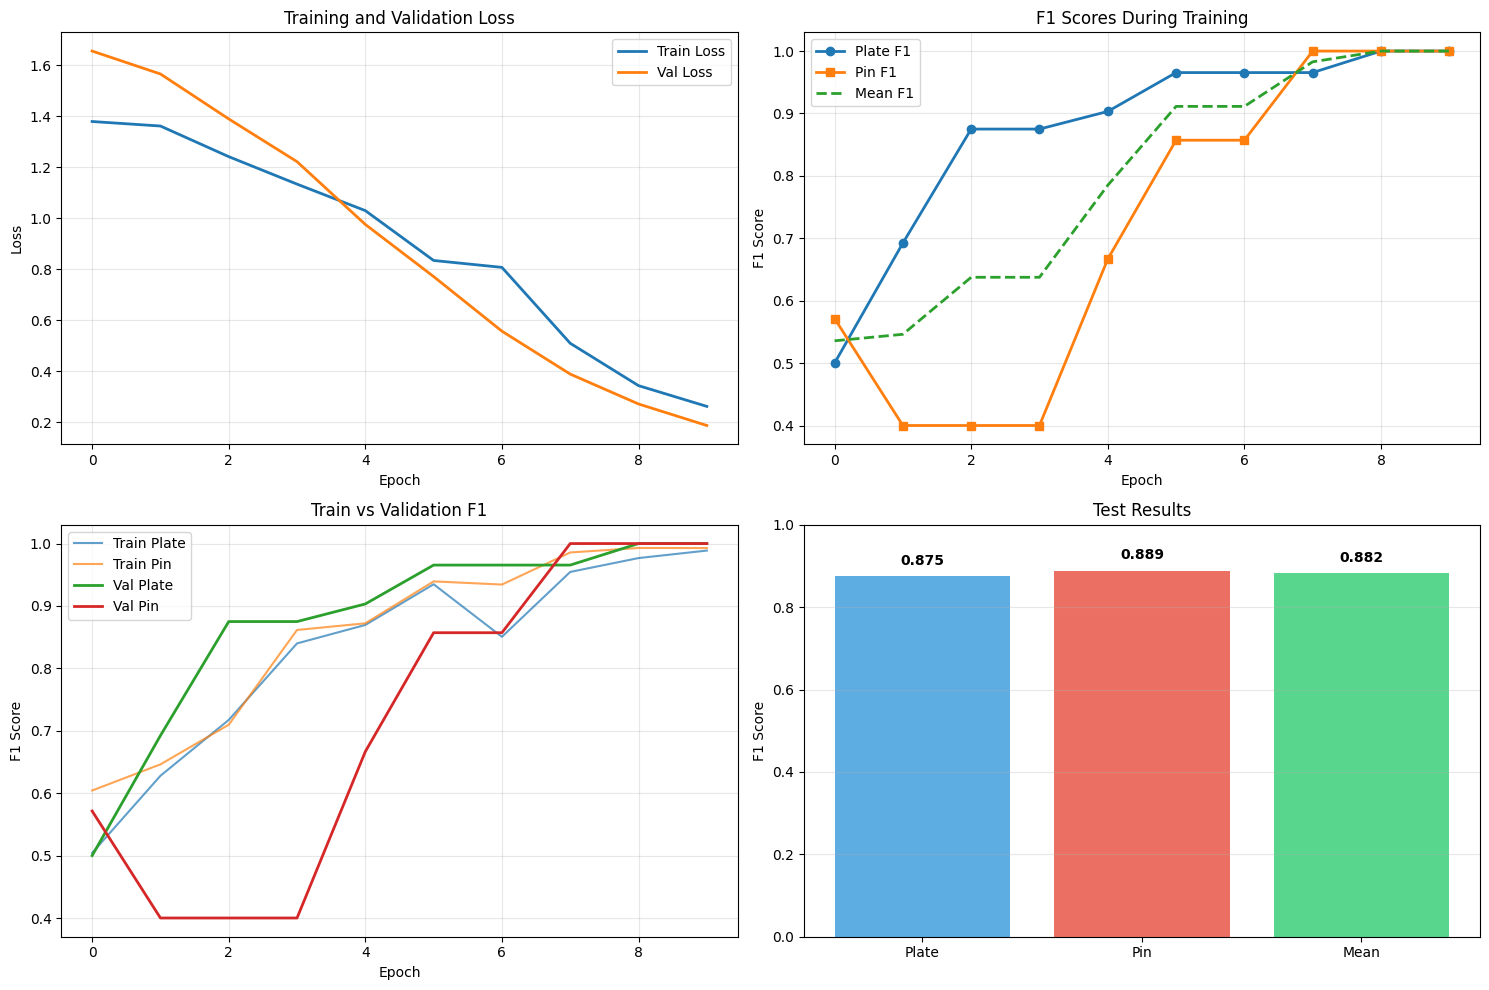

In [ ]:
plt.figure(figsize=(15, 10))

# График потерь
plt.subplot(2, 2, 1)
plt.plot([h['train_loss'] for h in history], label='Train Loss', linewidth=2)
plt.plot([h['val_loss'] for h in history], label='Val Loss', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True, alpha=0.3)

# График F1-score
plt.subplot(2, 2, 2)
plt.plot([h['val_f1_plate'] for h in history], label='Plate F1', linewidth=2, marker='o')
plt.plot([h['val_f1_pin'] for h in history], label='Pin F1', linewidth=2, marker='s')
plt.plot([h['mean_val_f1'] for h in history], label='Mean F1', linewidth=2, linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('F1 Score')
plt.title('F1 Scores During Training')
plt.legend()
plt.grid(True, alpha=0.3)

# График сравнения train/val F1
plt.subplot(2, 2, 3)
plt.plot([h['train_f1_plate'] for h in history], label='Train Plate', linewidth=1.5, alpha=0.7)
plt.plot([h['train_f1_pin'] for h in history], label='Train Pin', linewidth=1.5, alpha=0.7)
plt.plot([h['val_f1_plate'] for h in history], label='Val Plate', linewidth=2)
plt.plot([h['val_f1_pin'] for h in history], label='Val Pin', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('F1 Score')
plt.title('Train vs Validation F1')
plt.legend()
plt.grid(True, alpha=0.3)

# График тестовых результатов
plt.subplot(2, 2, 4)
metrics = ['Plate', 'Pin', 'Mean']
values = [test_metrics['plate']['f1'], test_metrics['pin']['f1'], test_metrics['mean_f1']]
colors = ['#3498db', '#e74c3c', '#2ecc71']
bars = plt.bar(metrics, values, color=colors, alpha=0.8)
plt.ylabel('F1 Score')
plt.title('Test Results')
plt.ylim([0, 1])

for bar, val in zip(bars, values):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.02,
             f'{val:.3f}', ha='center', va='bottom', fontweight='bold')

plt.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('/content/training_results.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
from google.colab import files
files.download('/content/best_multilabel_model.pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>